this notebook checks the trajectories computed in compute_trajectories.py
Environment: bt_env

In [1]:
import cdsapi
import xarray as xr
import pandas as pd
import numpy as np
import glob
import os
import sys
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# check trajectories

In [94]:
with xr.open_dataset('/home/jmayer/ACI_research/Code/resources_mesoscale_structure/bt_SEP.nc') as ds:
    bt_SEP = ds.load()

In [95]:
bt_SEP

<xarray.Dataset> Size: 7MB
Dimensions:          (time_startpoint: 12920, timestep: 15)
Coordinates:
  * timestep         (timestep) int64 120B -42 -36 -30 -24 -18 ... 24 30 36 42
  * time_startpoint  (time_startpoint) datetime64[ns] 103kB 2024-08-01T19:44:...
    orbit            (time_startpoint) <U6 310kB '01009E' '01009E' ... '08369E'
Data variables:
    lat_traj         (time_startpoint, timestep) float64 2MB nan nan ... nan nan
    lon_traj         (time_startpoint, timestep) float64 2MB nan nan ... nan nan
    plev_traj        (time_startpoint, timestep) float64 2MB nan nan ... nan nan
    datetime_traj    (time_startpoint, timestep) datetime64[ns] 2MB NaT ... NaT

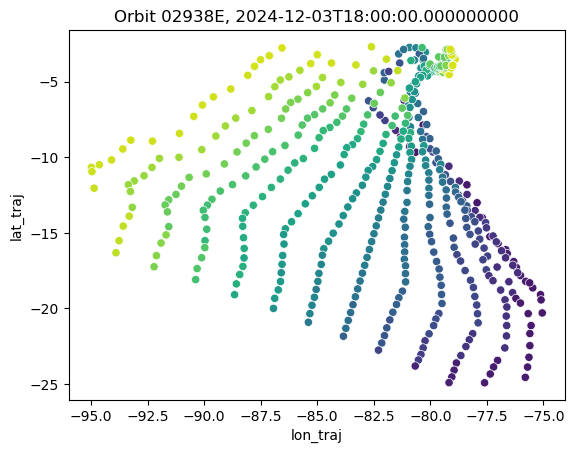

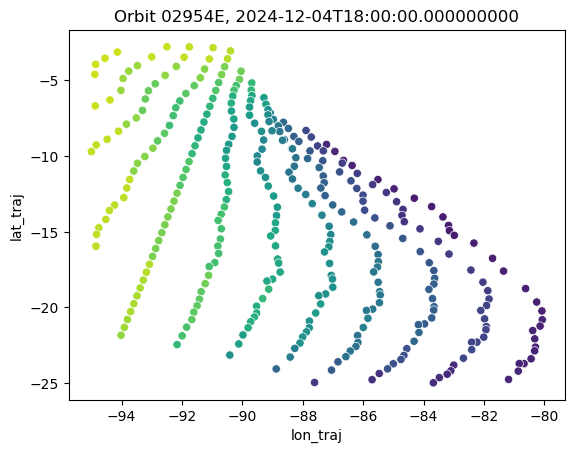

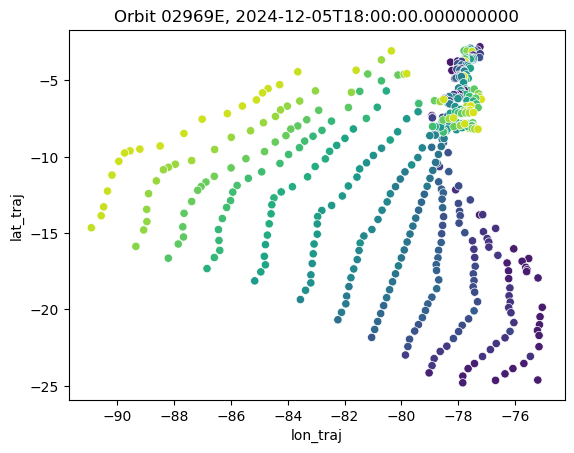

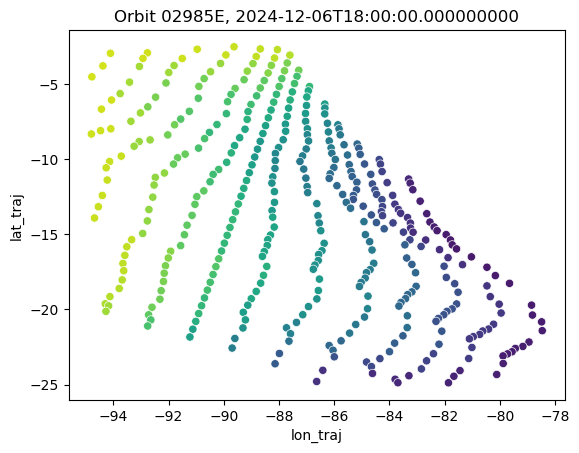

In [93]:
for orbit in np.unique(bt_SEP.orbit)[100:104]:
    bt_orbit = bt_SEP.where(bt_SEP.orbit == orbit, drop=True)
    for t in bt_orbit.time_startpoint:
        sns.scatterplot(data=bt_orbit.sel(time_startpoint=t), x='lon_traj', y='lat_traj', hue='datetime_traj', palette='viridis', legend=False)
    plt.title(f'Orbit {orbit}, {bt_orbit.sel(timestep=0).datetime_traj.values[0]}')
    plt.show()

# check judge along trajectories

In [6]:
with xr.open_dataset('/home/jmayer/ACI_research/Code/resources_mesoscale_structure/bt_with_goes_partial.nc') as ds:
    bt_with_goes = ds.load()

In [3]:
bt_with_goes

<xarray.Dataset> Size: 63MB
Dimensions:           (time_startpoint: 12920, timestep: 43)
Coordinates:
  * time_startpoint   (time_startpoint) datetime64[ns] 103kB 2024-08-01T19:44...
  * timestep          (timestep) int64 344B -42 -40 -38 -36 -34 ... 36 38 40 42
    orbit             (time_startpoint) <U6 310kB '01009E' '01009E' ... '08369E'
Data variables: (12/14)
    lat_traj          (time_startpoint, timestep) float64 4MB nan nan ... nan
    lon_traj          (time_startpoint, timestep) float64 4MB nan nan ... nan
    plev_traj         (time_startpoint, timestep) float64 4MB nan nan ... nan
    datetime_traj     (time_startpoint, timestep) datetime64[ns] 4MB NaT ... NaT
    goes_cats         (time_startpoint, timestep) float64 4MB nan nan ... nan
    goes_cert         (time_startpoint, timestep) float64 4MB nan nan ... nan
    ...                ...
    goes_ot_gt_1      (time_startpoint, timestep) float64 4MB nan nan ... nan
    goes_ot_gt_5      (time_startpoint, timestep) float64 4MB nan nan ... nan
    goes_y_idx        (time_startpoint, timestep) float64 4MB nan nan ... nan
    goes_x_idx        (time_startpoint, timestep) float64 4MB nan nan ... nan
    goes_lon_mid      (time_startpoint, timestep) float64 4MB nan nan ... nan
    goes_lat_mid      (time_startpoint, timestep) float64 4MB nan nan ... nan

In [4]:
bt_with_goes.goes_x_idx.dropna(dim='time_startpoint', how='all')

<xarray.DataArray 'goes_x_idx' (time_startpoint: 9003, timestep: 43)> Size: 3MB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(9003, 43))
Coordinates:
  * time_startpoint  (time_startpoint) datetime64[ns] 72kB 2024-08-01T19:44:2...
  * timestep         (timestep) int64 344B -42 -40 -38 -36 -34 ... 36 38 40 42
    orbit            (time_startpoint) <U6 216kB '01009E' '01009E' ... '06221E'

In [5]:
np.unique(bt_with_goes.orbit)

array(['01009E', '01024E', '01040E', '01056E', '01071E', '01087E',
       '01102E', '01133E', '01164E', '01180E', '01195E', '01211E',
       '01227E', '01242E', '01258E', '01273E', '01289E', '01304E',
       '01320E', '01335E', '01351E', '01367E', '01382E', '01398E',
       '01413E', '01460E', '01475E', '01491E', '01522E', '01538E',
       '01553E', '01569E', '01584E', '01600E', '01616E', '01631E',
       '01647E', '01678E', '01693E', '01709E', '01724E', '01740E',
       '01756E', '01771E', '01787E', '01833E', '01849E', '01864E',
       '01880E', '01896E', '01911E', '01927E', '01942E', '02005E',
       '02020E', '02036E', '02051E', '02067E', '02082E', '02160E',
       '02176E', '02191E', '02222E', '02238E', '02253E', '02269E',
       '02285E', '02300E', '02316E', '02331E', '02378E', '02394E',
       '02409E', '02425E', '02440E', '02456E', '02471E', '02487E',
       '02518E', '02534E', '02549E', '02565E', '02596E', '02627E',
       '02642E', '02658E', '02674E', '02689E', '02705E', '0272

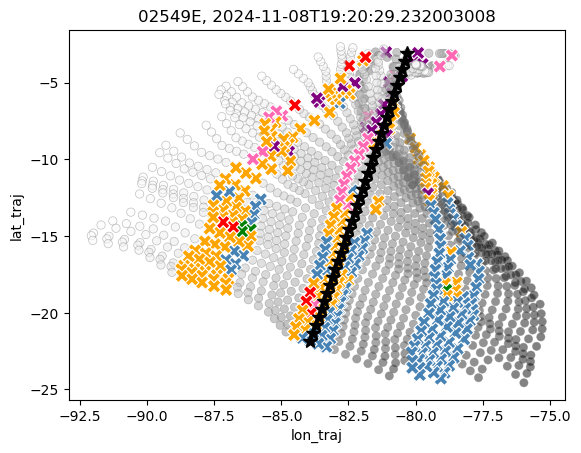

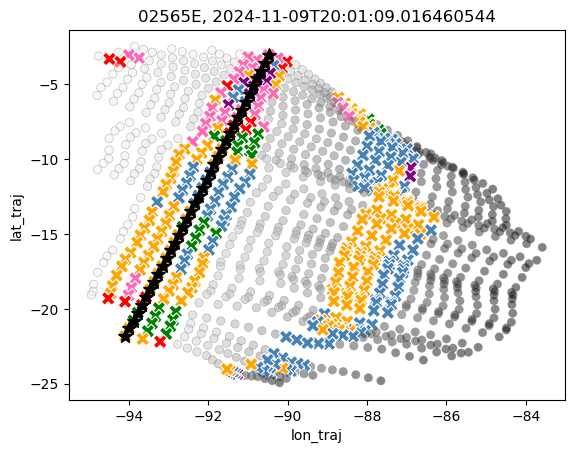

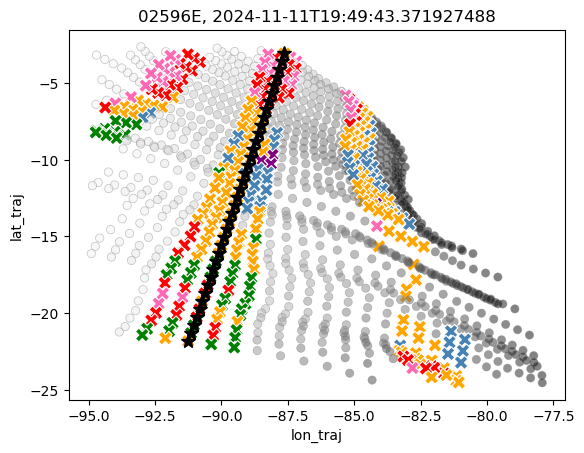

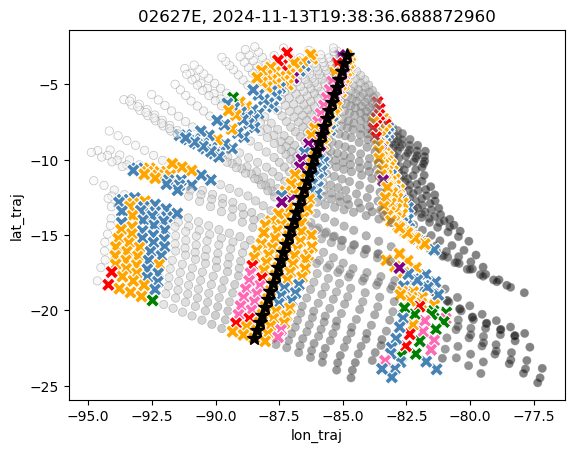

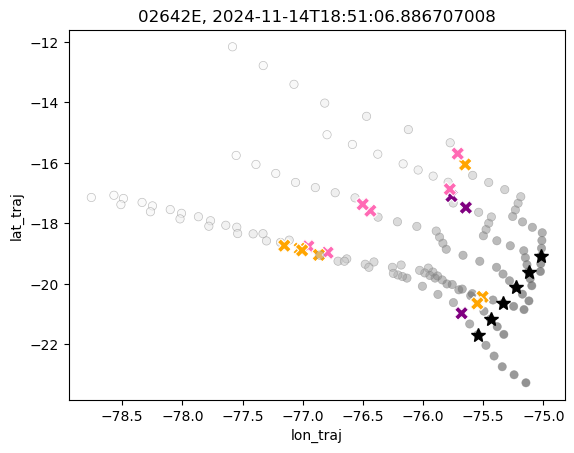

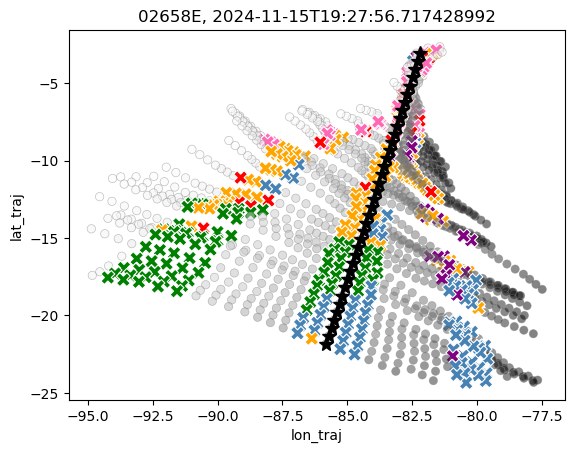

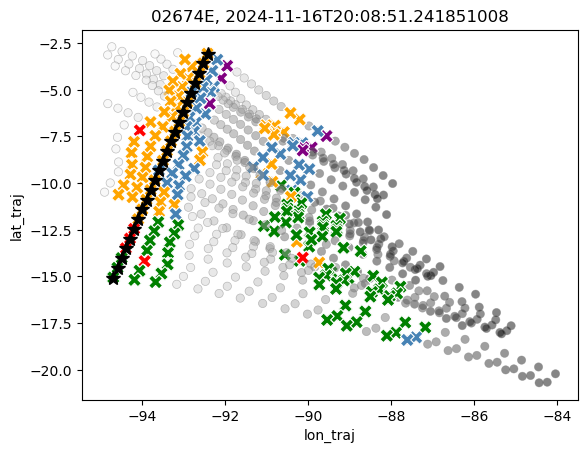

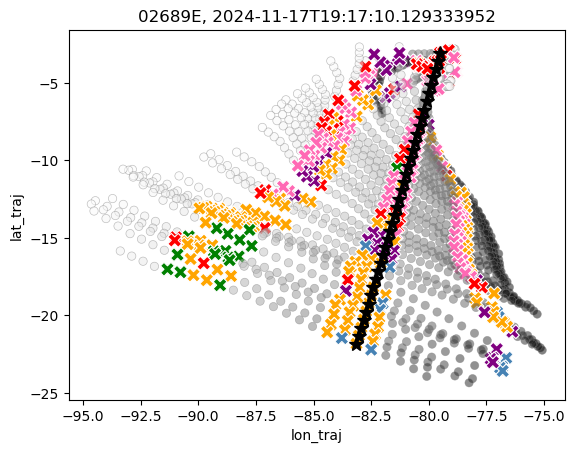

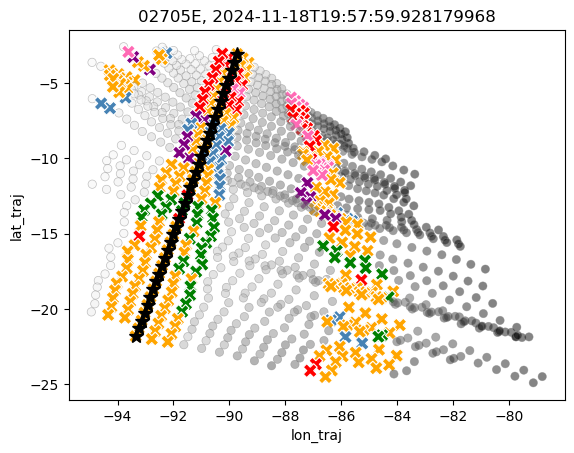

/tmp/ipykernel_961692/4006162430.py:10: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)
/tmp/ipykernel_961692/4006162430.py:10: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)
/tmp/ipykernel_961692/4006162430.py:10: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)


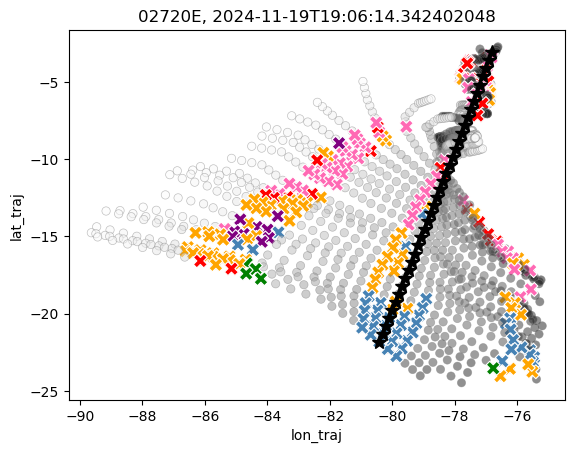

In [7]:
palette_goes_cats = {0: 'purple', 1: 'steelblue', 2: 'green', 3: 'orange', 4: 'red', 5: 'hotpink', np.nan: 'grey'}

for orbit in np.unique(bt_with_goes.orbit)[80:90]:
    bt_orbit = bt_with_goes.where(bt_with_goes.orbit == orbit, drop=True)
    for i in range(len(bt_orbit.time_startpoint)):
        tmp = bt_orbit.isel(time_startpoint=i)
        alpha = 1.0
        sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='datetime_traj', palette='Greys_r', alpha=0.5, edgecolor='Grey', legend=False)
        plt.plot([tmp.sel(timestep=0).lon_traj.values], [tmp.sel(timestep=0).lat_traj.values], color='black', marker='*', markersize=10, alpha=alpha)
        sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)
    plt.title(f'{orbit}, {bt_orbit.time_startpoint.values[0]}')
    plt.show()

NameError: name 'palette_goes_cats' is not defined

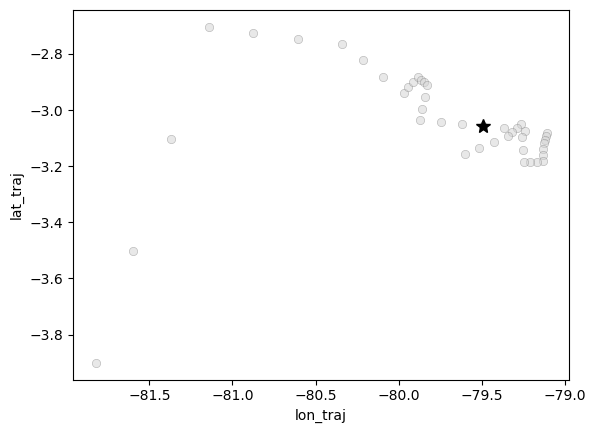

In [5]:
for orbit in np.unique(bt_with_goes.orbit)[50:60]:
    bt_orbit = bt_with_goes.where(bt_with_goes.orbit == orbit, drop=True)
    for i in range(len(bt_orbit.time_startpoint)):
        tmp = bt_orbit.isel(time_startpoint=i)
        alpha = 1.0
        sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', color='lightgrey', alpha=0.5, edgecolor='Grey', legend=False)
        plt.plot([tmp.sel(timestep=0).lon_traj.values], [tmp.sel(timestep=0).lat_traj.values], color='black', marker='*', markersize=10, alpha=alpha)
        sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, size='goes_ot_gt_5', marker='X', alpha=alpha)
    plt.title(f'{orbit}, {bt_orbit.time_startpoint.values[0]}')
    plt.show()

# plot time series of GOES along trajectories

In [2]:
from scipy.ndimage import zoom
import seaborn as sns
import matplotlib.pyplot as plt
import sys
sys.path.append('/home/jmayer/ACI_research/Code/mesoscale_structure/judge_for_goes')
from functions_for_goes import crop_goes_to_latlon_box, convert_radiance_to_brightness_temp

# SEP region (Southeast Pacific)
lat_bounds = (-22.5, -2.5)
lon_bounds = (-95, -75)

In [3]:
orbit = '06766E'
include_IR_obs = True
bt_orbit = bt_with_goes.where(bt_with_goes.orbit == orbit, drop=True)
bt_orbit

NameError: name 'bt_with_goes' is not defined

In [8]:
orbits_with_co_transitions = [
    #'01009E', '01040E', '01056E', '01071E', '01087E', '01102E',
    #'01133E', '01164E', '01180E', '01211E', 
    '01227E', '01242E',
    '01258E', '01273E', '01289E', '01304E', '01320E', '01351E',
    '01367E', '01382E', '01460E', '01491E', '01522E', '01538E',
    '01553E', '01569E', '01600E', '01631E', '01647E', '01678E',
    '01693E', '01709E', '01740E', '01756E', '01771E', '01787E',
    '01833E', '01849E', '01942E', '02005E', '02036E', '02160E',
    '02238E', '02285E', '02409E', '02425E', '02440E', '02456E',
    '02471E', '02487E', '02518E', '02565E', '02674E', '02720E',
    '02876E', '03078E', '03094E', '03187E', '03203E', '04105E',
    '04152E', '04214E', '04634E', '05132E', '05272E', '05303E',
    '05412E', '05428E', '05443E', '05521E', '05537E', '05583E',
    '05630E', '05646E', '05677E', '05692E', '05708E', '05723E',
    '05739E', '05786E', '05817E', '05848E', '05972E', '05988E',
    '06019E', '06050E', '06066E', '06128E', '06159E', '06175E',
    '06190E', '06206E', '06237E', '06268E', '06299E', '06315E',
    '06330E', '06346E', '06361E', '06377E', '06408E', '06424E',
    '06439E', '06455E', '06470E', '06486E', '06501E', '06517E',
    '06548E', '06564E', '06579E', '06595E', '06626E', '06688E',
    '06704E', '06719E', '06766E', '06797E', '06813E', '06828E',
    '06844E', '06875E', '06906E', '06937E', '06953E', '06984E',
    '07030E', '07046E', '07077E', '07093E', '07108E', '07124E',
    '07155E', '07279E', '07295E', '07326E', '07342E', '07373E',
    '07388E', '07404E', '07435E', '07466E', '07482E', '07497E',
    '07513E', '07575E', '07591E', '07622E', '07637E', '07653E',
    '07684E', '07715E', '07746E', '07793E', '07886E', '07933E',
    '08073E', '08120E', '08151E', '08291E', '08353E']

In [ ]:
orbit = '06766E'
include_IR_obs = True
palette_goes_cats = {0: 'black', 1: 'blue', 2: 'orange', 3: 'black', 4: 'black', 5: 'black', np.nan: 'grey', -1: 'grey'}

for orbit in orbits_with_co_transitions:
    bt_orbit = bt_with_goes.where(bt_with_goes.orbit == orbit, drop=True)

    overpass_date = str(bt_orbit.time_startpoint[0].dt.strftime('%Y%m%d').values)
    valid_dates = np.abs(bt_orbit.datetime_traj - bt_orbit.time_startpoint[0]) < np.timedelta64(42, 'h')
    bt_orbit = bt_orbit.where(valid_dates)
    dates0 = np.unique(bt_orbit.datetime_traj[0].dt.strftime('%Y%m%d').dropna('timestep'))
    dates1 = np.unique(bt_orbit.datetime_traj[-1].dt.strftime('%Y%m%d').dropna('timestep'))
    dates = np.unique(np.concatenate((dates0, dates1)))


    if include_IR_obs:
        goes_times = ['00', '02', '04', '06', '08', '10', '12', '14', '16', '18', '20', '22']
    else:
        goes_times = ['14', '16', '18', '20', '22']
    overpass_time = '18'
    #overpass_time = str(bt_orbit.time_startpoint[0].dt.strftime('%H%M').values)
    for date in dates:
        if date < '20250407':
            goes_id = '16'
        else:
            goes_id = '19'
        for goes_time in goes_times: # GOES times in UTC hours
            timestep = (pd.to_datetime(date+str(goes_time).zfill(2)+'00') - pd.to_datetime(overpass_date+str(overpass_time).zfill(2)+'00')).total_seconds() / 3600
            print(timestep)
            if timestep < bt_orbit.timestep.min() or timestep > bt_orbit.timestep.max():
                continue

            with xr.open_dataset(f'/home/jmayer/Object_Data/GOES{goes_id}/{date[0:4]}/{date[4:6]}/goes{goes_id}_COD2KMF_{date}_{goes_time}00.nc') as ds:
                # Crop to your region
                ds_COD_cropped = crop_goes_to_latlon_box(ds, lat_bounds, lon_bounds)

            if include_IR_obs:
                with xr.open_dataset(f'/home/jmayer/Object_Data/GOES{goes_id}/{date[0:4]}/{date[4:6]}/goes{goes_id}_C14_RadF_{date}_{goes_time}00.nc') as ds:
                    # Convert to brightness temperature
                    ds = convert_radiance_to_brightness_temp(ds)
                    # Crop to your region
                    ds_14_cropped = crop_goes_to_latlon_box(ds, lat_bounds, lon_bounds)

            if include_IR_obs:
                fig, axs = plt.subplots(1, 2, figsize=(20, 7))
                plt.suptitle(f'{date} {goes_time} UTC, GOES-19')

                # Store the return value from pcolormesh
                img1 = axs[0].pcolormesh(ds_COD_cropped.longitude, ds_COD_cropped.latitude, ds_COD_cropped['COD'], 
                            vmax=35, cmap='Greys_r', shading='auto')
                # Fix: Use 'mappable' parameter, not 'img'
                plt.colorbar(img1, ax=axs[0], label='Cloud Optical Depth (COD)')

                img2 = axs[1].pcolormesh(ds_14_cropped.longitude, ds_14_cropped.latitude, ds_14_cropped['BT'], 
                            vmin=280, vmax=290, cmap='Greys', shading='auto')
                plt.colorbar(img2, ax=axs[1], label='Band 14 Brightness Temperature (11.19 $\mu$m) / K')

                for ax in axs:
                    ax.set_xlabel('Longitude')
                    ax.set_ylabel('Latitude')
                    ax.set_ylim(lat_bounds)
                    ax.set_xlim(lon_bounds)

                    bt_startpoint = bt_orbit.sel(timestep=0)
                    ax.plot(bt_startpoint.lon_traj.values, bt_startpoint.lat_traj.values, color='red', lw=3)#, label=f'EC track ({orbit})')

                    for i in range(len(bt_orbit.time_startpoint)//5):
                        traj = bt_orbit.isel(time_startpoint=i*5).sortby('timestep')
                        ax.plot(traj.lon_traj.values, traj.lat_traj.values, color='blue', lw=1, alpha=0.7)

                    bt_at_sel_timestep = bt_orbit.sel(timestep=timestep)
                    goes_cats = bt_orbit.sel(timestep=timestep).goes_cats.fillna(-1)
                    #ax.scatter(bt_at_sel_timestep.lon_traj.values, bt_at_sel_timestep.lat_traj.values, color='blue', marker='o', alpha=0.7) #, label=f'{timestep}h from EC overpass')
                    sns.scatterplot(ax=ax, x=bt_at_sel_timestep.lon_traj, y=bt_at_sel_timestep.lat_traj, 
                                    hue=goes_cats, palette=palette_goes_cats, marker='o', zorder=2, alpha=1, legend=False) #, label=f'{timestep}h from EC overpass')

                    ax.legend(handles=[plt.Line2D([0], [0], color='red', lw=3, label='EC track'),
                        plt.Line2D([0], [0], marker='o', color='w', label=f'$\Delta$t = {timestep}h',
                            markerfacecolor='grey', markersize=10)],
                        loc='upper right')

                os.makedirs(f'/home/jmayer/ACI_research/Code/mesoscale_structure/figures_bt/{orbit}/', exist_ok=True)
                plt.savefig(f'/home/jmayer/ACI_research/Code/mesoscale_structure/figures_bt/{orbit}/bt_{orbit}_{date}_{goes_time}00.png', dpi=300)
                plt.show()

            else:
                plt.figure(figsize=(10, 7))
                plt.pcolormesh(ds_COD_cropped.longitude, ds_COD_cropped.latitude, ds_COD_cropped['COD'], 
                            vmax=35, cmap='Greys_r', shading='auto')
                plt.colorbar(label='Cloud Optical Depth (COD)')
                plt.xlabel('Longitude')
                plt.ylabel('Latitude')
                plt.title(f'{date} {goes_time} UTC, GOES-19')

                bt_startpoint = bt_orbit.sel(timestep=0)
                plt.plot(bt_startpoint.lon_traj.values, bt_startpoint.lat_traj.values, color='red', lw=3)#, label=f'EC track ({orbit})')

                bt_at_sel_timestep = bt_orbit.sel(timestep=timestep)
                #plt.scatter(bt_at_sel_timestep.lon_traj.values, bt_at_sel_timestep.lat_traj.values, color='blue', marker='o', alpha=0.7, label=f'{timestep}h from EC overpass')
                sns.scatterplot(x=bt_at_sel_timestep.lon_traj, y=bt_at_sel_timestep.lat_traj, 
                                hue=bt_at_sel_timestep.goes_cats_match, palette=palette_goes_cats, marker='o', alpha=0.9, legend=False) #, label=f'{timestep}h from EC overpass')

                for i in range(len(bt_orbit.time_startpoint)//5):
                    traj = bt_orbit.isel(time_startpoint=i*5).sortby('timestep')
                    plt.plot(traj.lon_traj.values, traj.lat_traj.values, color='blue', lw=1, alpha=0.7)

                plt.legend(handles=[plt.Line2D([0], [0], color='red', lw=3, label='EC track'),
                    plt.Line2D([0], [0], marker='o', color='w', label=f'{timestep}h from EC overpass',
                        markerfacecolor='grey', markersize=10)],
                    loc='upper right')
                plt.ylim(lat_bounds)
                plt.xlim(lon_bounds)
                os.makedirs(f'/home/jmayer/ACI_research/Code/mesoscale_structure/figures_bt/{orbit}/', exist_ok=True)
                plt.savefig(f'/home/jmayer/ACI_research/Code/mesoscale_structure/figures_bt/{orbit}/bt_{orbit}_{date}_{goes_time}00.png', dpi=300)
                plt.show()

            plt.close('all')
        # clean up memory
        import gc
        gc.collect()

<>:56: SyntaxWarning: invalid escape sequence '\m'
<>:78: SyntaxWarning: invalid escape sequence '\D'
<>:56: SyntaxWarning: invalid escape sequence '\m'
<>:78: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_3289371/49733392.py:56: SyntaxWarning: invalid escape sequence '\m'
  plt.colorbar(img2, ax=axs[1], label='Band 14 Brightness Temperature (11.19 $\mu$m) / K')
/tmp/ipykernel_3289371/49733392.py:78: SyntaxWarning: invalid escape sequence '\D'
  plt.Line2D([0], [0], marker='o', color='w', label=f'$\Delta$t = {timestep}h',


-42.0


/home/jmayer/ACI_research/Code/mesoscale_structure/judge_for_goes/functions_for_goes.py:112: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  y_max = min(ds.dims['y'] - 1, y_max + padding)
/home/jmayer/ACI_research/Code/mesoscale_structure/judge_for_goes/functions_for_goes.py:114: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  x_max = min(ds.dims['x'] - 1, x_max + padding)


Original shape: FrozenMappingWarningOnValuesAccess({'y': 5424, 'x': 5424, 'number_of_time_bounds': 2, 'number_of_image_bounds': 2, 'number_of_LZA_bounds': 2, 'number_of_SZA_bounds': 2})
Cropped shape: FrozenMappingWarningOnValuesAccess({'y': 1077, 'x': 1094, 'number_of_time_bounds': 2, 'number_of_image_bounds': 2, 'number_of_LZA_bounds': 2, 'number_of_SZA_bounds': 2})
Lat range: -23.01 to -2.29
Lon range: -97.38 to -74.81


/home/jmayer/ACI_research/Code/mesoscale_structure/judge_for_goes/functions_for_goes.py:112: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  y_max = min(ds.dims['y'] - 1, y_max + padding)
/home/jmayer/ACI_research/Code/mesoscale_structure/judge_for_goes/functions_for_goes.py:114: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  x_max = min(ds.dims['x'] - 1, x_max + padding)


Original shape: FrozenMappingWarningOnValuesAccess({'y': 5424, 'x': 5424, 'number_of_time_bounds': 2, 'number_of_image_bounds': 2, 'band': 1, 'number_of_harmonization_coefficients': 3, 'num_star_looks': 24})
Cropped shape: FrozenMappingWarningOnValuesAccess({'y': 1077, 'x': 1094, 'number_of_time_bounds': 2, 'number_of_image_bounds': 2, 'band': 1, 'number_of_harmonization_coefficients': 3, 'num_star_looks': 24})
Lat range: -23.01 to -2.29
Lon range: -97.38 to -74.81
-40.0


... (1,403 outputs left out)

Original shape: FrozenMappingWarningOnValuesAccess({'y': 5424, 'x': 5424, 'number_of_time_bounds': 2, 'number_of_image_bounds': 2, 'band': 1, 'number_of_harmonization_coefficients': 3, 'num_star_looks': 24})
Cropped shape: FrozenMappingWarningOnValuesAccess({'y': 1077, 'x': 1094, 'number_of_time_bounds': 2, 'number_of_image_bounds': 2, 'band': 1, 'number_of_harmonization_coefficients': 3, 'num_star_looks': 24})
Lat range: -23.01 to -2.29
Lon range: -97.38 to -74.81
-32.0


/home/jmayer/ACI_research/Code/mesoscale_structure/judge_for_goes/functions_for_goes.py:112: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  y_max = min(ds.dims['y'] - 1, y_max + padding)
/home/jmayer/ACI_research/Code/mesoscale_structure/judge_for_goes/functions_for_goes.py:114: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  x_max = min(ds.dims['x'] - 1, x_max + padding)


Original shape: FrozenMappingWarningOnValuesAccess({'y': 5424, 'x': 5424, 'number_of_time_bounds': 2, 'number_of_image_bounds': 2, 'number_of_LZA_bounds': 2, 'number_of_SZA_bounds': 2})
Cropped shape: FrozenMappingWarningOnValuesAccess({'y': 1077, 'x': 1094, 'number_of_time_bounds': 2, 'number_of_image_bounds': 2, 'number_of_LZA_bounds': 2, 'number_of_SZA_bounds': 2})
Lat range: -23.01 to -2.29
Lon range: -97.38 to -74.81


: 